# Task-1 (Week-6)

**Date** :- (19-11-26)

**Dataset** :- 'Admission_Prediction.csv'

**Objective** :- Convert highly optimized university admission prediction models into serialized formats (pickle/joblib) ensuring compatibility and efficiency for deployment across diverse platforms.

In [1]:
# importing required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
import pickle
import joblib

In [2]:
# loading the dataset
df = pd.read_csv('Admission_Prediction.csv')
df.head()

,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Year,Application_Date,University_Name,region,Admission Status,Duration_Months,Dropout_Event,Dropout-free survival,Survival_Data_Note
0,104,317,104,2,4.5,4.0,8.47,0,0.57,2022,2022-01-03,Indian Institute of Technology Bombay,West,Rejected,36,0,0.536473,SIMULATED proxy derived from admission feature...
1,170,311,99,2,2.5,3.0,7.98,0,0.65,2022,2022-01-09,Indian Institute of Technology Delhi,North,Rejected,18,1,0.973000,SIMULATED proxy derived from admission feature...
2,138,316,100,2,1.5,3.0,8.16,1,0.71,2022,2022-01-12,Indian Institute of Technology Delhi,North,Rejected,33,0,0.597989,SIMULATED proxy derived from admission feature...
3,147,315,105,3,2.0,2.5,8.48,0,0.75,2022,2022-01-13,Indian Institute of Technology Delhi,North,Accepted,33,0,0.597989,SIMULATED proxy derived from admission feature...
4,117,299,102,3,4.0,3.5,8.62,0,0.56,2022,2022-01-14,Indian Institute of Technology Delhi,North,Rejected,28,1,0.734170,SIMULATED proxy derived from admission feature...


In [3]:
# data preprocessing and feature selection
features = ['GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research']
X = df[features]
y = (df['Admission Status'] == 'Accepted').astype(int)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
# model training and hyperparameter optimization
param_grid = {'n_estimators': [50, 100], 'max_depth': [3, 5, 8], 'random_state': [42]}
grid = GridSearchCV(RandomForestClassifier(), param_grid, cv=3)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
best_model

,n_estimators,50
,criterion,'gini'
,max_depth,3
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [5]:
# evaluating model performance
y_pred = best_model.predict(X_test)
print('accuracy:', accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

accuracy: 0.7
              precision    recall  f1-score   support

           0       0.69      0.89      0.78       117
           1       0.73      0.43      0.55        83

    accuracy                           0.70       200
   macro avg       0.71      0.66      0.66       200
weighted avg       0.71      0.70      0.68       200



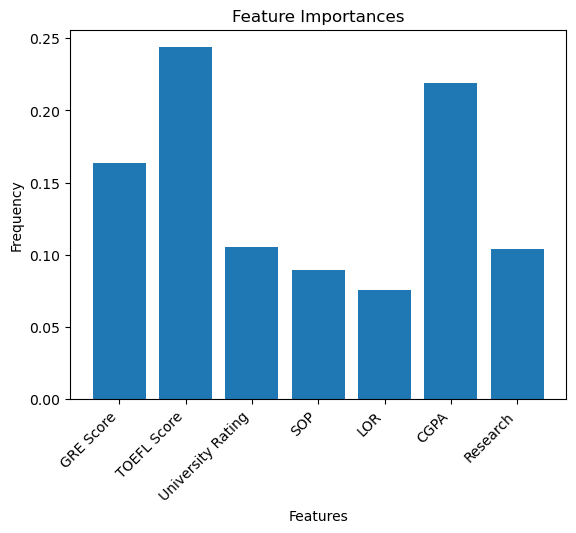

In [17]:
# plotting feature importances
importances = best_model.feature_importances_
plt.bar(features, importances)
plt.xticks(rotation=45, ha="right")
plt.xlabel("Features")
plt.ylabel("Frequency")
plt.title('Feature Importances')
plt.show()

In [7]:
# saving models using pickle and joblib
with open('admission_model.pkl', 'wb') as f:
    pickle.dump(best_model, f)
joblib.dump(best_model, 'admission_model.joblib')
print('models serialized successfully')

models serialized successfully


In [8]:
# loading serialized models and verifying predictions
with open('admission_model.pkl', 'rb') as f:
    pickle_model = pickle.load(f)
joblib_model = joblib.load('admission_model.joblib')
sample = X_test.iloc[:5]
print('pickle predictions:', pickle_model.predict(sample))
print('joblib predictions:', joblib_model.predict(sample))

pickle predictions: [0 0 0 0 0]
joblib predictions: [0 0 0 0 0]
